# Green Hydrogen Course Project
### Jodhpur | Solar PV + pressurised alkaline electrolyser | Techno-economic and environmental assessment



## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
np.random.seed(2026)
plt.rcParams['figure.figsize'] = (9, 4)

## 2. Load the input register
Upload `input_data_register.csv` to the Colab session, or use the fallback table below. Values marked as assumptions in the report must not be described as measured values.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Upload input_data_register.csv

Saving input_data_register.csv to input_data_register.csv


In [ ]:
# The register is also represented here so the notebook can run if upload is skipped.
register = pd.DataFrame([
 ['PV installed cost',46200,'INR/kWp','Sourced; FX assumed'],
 ['Electrolyser system cost',800,'USD/kW','IRENA range midpoint'],
 ['Scale exponent',-0.144,'-','Derived; approximate'],
 ['Stack share of system cost',45,'%','IRENA; varies by maker'],
 ['SEC0',52,'kWh/kg','Chosen within IRENA range; plus 3% fixed auxiliary load'],
 ['Minimum load',20,'% rated','Assumption'],
 ['Stack life',60000,'operating hours','IRENA reference'],
 ['Water use',20,'kg/kg H2','IRENA range; 9 kg/kg stoichiometric'],
 ['Water cost',100,'INR/m3','Derived; local tariff not checked'],
 ['Discount rate',10,'%','Assumption'],
 ['Project life',25,'years','Assumption'],
 ['PV yield',1777,'kWh/kWp/year','Synthetic pvlib proxy; not NASA POWER'],
 ['INR/USD',88,'INR/USD','Assumption'],
 ['PV embodied emissions',1500,'kg CO2e/kWp','Assumption'],
 ['Electrolyser embodied emissions',250,'kg CO2e/kW','Assumption'],
 ['Hydrogen GWP100',11.6,'-','Sand et al.'],
 ['Leak rate',0.5,'%','Assumption']
], columns=['Parameter','Value','Unit','Basis / limitation'])
try:
    fname = next((f for f in uploaded if f.lower().endswith('.csv')), None)
    if fname:
        register_raw = pd.read_csv(fname)
        display(register_raw)
    else:
        display(register)
except NameError:
    display(register)

,Parameter,Value,Unit,Source / URL,Type,Limitation / confidence
0,PV installed cost,46 200,INR/kWp,IRENA 2025 [2]: India USD 525/kW x INR 88,Sourced (FX assumed),Basis (DC/AC) unclear
1,Electrolyser system cost,800 (scale factor below 10 MW),USD/kW,IRENA 2020 [1]: 500-1000,"Sourced range, midpoint chosen",2020 prices
2,Scale exponent,-0.144,-,"Derived from IRENA [1]: 1 to 20 MW, >1/3 cheaper",Derived,Rough
3,Stack share of system cost,45,%,IRENA [1] (about 45%),Sourced,Varies by maker
4,"Other component shares, compression 12%, insta...",as stated,%,Own estimates,Assumed,Low; tested only for compression
5,System energy use SEC0 (+3% fixed aux),52 (+3%),kWh/kg,Within IRENA 50-78 [1],Chosen in range,Constant with load
6,Minimum load,20,% of rated,Own assumption,Assumed,Check with vendor
7,Stack life,60 000,operating h,IRENA [1],Sourced,Varies with duty cycle
8,Water use,20 (9 stoich.),kg/kg H2,IRENA [1]: 18-24,Sourced,-
9,Water cost,100,INR/m3,IRENA [1]: about USD 1/m3,Derived,Jodhpur tariff not checked


## 3. Build a transparent hourly PV proxy


In [ ]:
# Generate 365 x 24 hourly timestamps
time = pd.date_range('2023-01-01', periods=8760, freq='h')
pv = pd.DataFrame({'timestamp':time})
pv['day'] = pv.timestamp.dt.dayofyear
pv['hour'] = pv.timestamp.dt.hour

# Seasonal and diurnal pattern with lower monsoon irradiance
daylight = np.maximum(0, np.sin(np.pi*(pv['hour'].to_numpy()-6)/12))
season = 0.88 + 0.12*np.cos(2*np.pi*(pv['day'].to_numpy()-172)/365)
monsoon = np.where(pv.timestamp.dt.month.isin([7,8]), 0.78, 1.0)
cloud = np.clip(np.random.default_rng(2026).normal(1,0.12,8760),0.5,1.2)
shape = daylight*season*monsoon*cloud

# PV AC output per kWp; scale annual sum to the reported 1,777 kWh/kWp.
pv['pv_kw_per_kwp'] = shape
pv['pv_kw_per_kwp'] *= 1777 / pv['pv_kw_per_kwp'].sum()
print('Hours:',len(pv))
print('Annual yield (kWh/kWp):',pv.pv_kw_per_kwp.sum())
pv.head()

Hours: 8760
Annual yield (kWh/kWp): 1777.0000000000002


,timestamp,day,hour,pv_kw_per_kwp
0,2023-01-01 00:00:00,1,0,0.0
1,2023-01-01 01:00:00,1,1,0.0
2,2023-01-01 02:00:00,1,2,0.0
3,2023-01-01 03:00:00,1,3,0.0
4,2023-01-01 04:00:00,1,4,0.0


In [ ]:
pv.to_csv('pv_hourly_proxy_reconstructed.csv',index=False)

## 4. PV model assumptions and plots
The report uses a temperature coefficient of −0.35%/°C and an aggregate loss factor of 0.899. Its stated yield is 1,777 kWh/kWp/year. The proxy above is scaled to that annual yield, so the temperature and loss model are not independently recomputed from raw weather data.

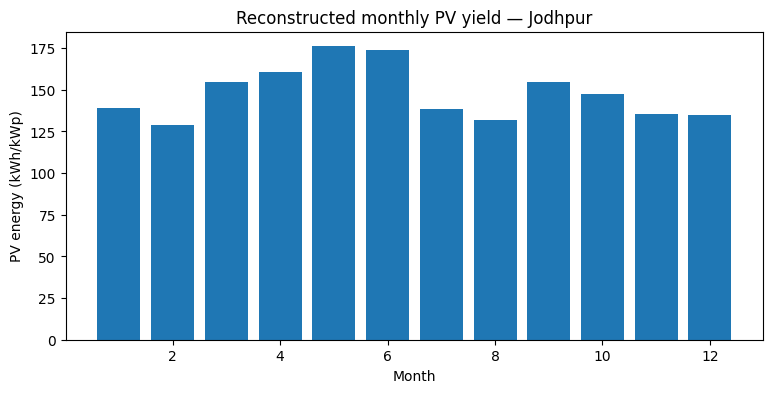

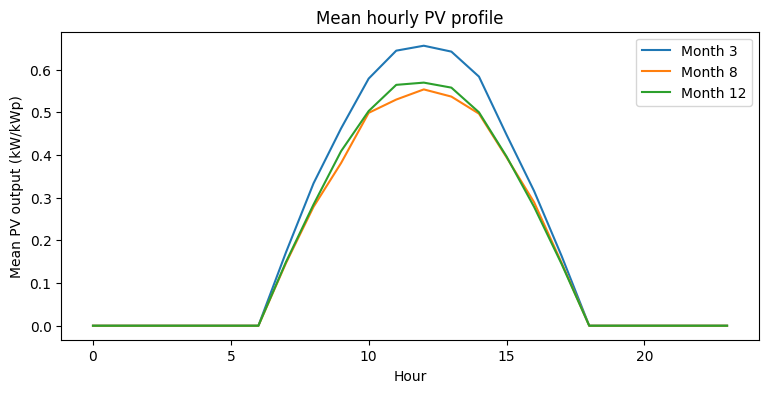

In [ ]:
monthly = pv.assign(month=pv.timestamp.dt.month).groupby('month')['pv_kw_per_kwp'].sum()
plt.bar(monthly.index,monthly.values)
plt.xlabel('Month'); plt.ylabel('PV energy (kWh/kWp)')
plt.title('Reconstructed monthly PV yield — Jodhpur')
plt.show()

hourly_mean = pv.assign(hour=pv.timestamp.dt.hour,month=pv.timestamp.dt.month).pivot_table(
    index='hour',columns='month',values='pv_kw_per_kwp',aggfunc='mean')
for m in [3,8,12]:
    plt.plot(hourly_mean.index,hourly_mean[m],label=f'Month {m}')
plt.xlabel('Hour'); plt.ylabel('Mean PV output (kW/kWp)')
plt.title('Mean hourly PV profile'); plt.legend(); plt.show()

## 5. Electrolyser operation
Base case: 10 MWp PV, 5 MW electrolyser, 20% minimum load, 3% fixed auxiliary load whenever running, and SEC₀ = 52 kWh/kg. The report defines hydrogen production as `(P_el − 0.03 × P_rated) / 52`.

In [ ]:
PV_MWp = 10
EL_MW = 5
minimum_load_fraction = 0.20
aux_fraction = 0.03
SEC0_kWh_kg = 52

# Scale the synthetic hourly PV shape to 10 MWp.
pv['PV_power_MW'] = pv['pv_kw_per_kwp'] * PV_MWp

# Hourly operating logic from the report.
pv['EL_input_MW'] = np.where(
    pv['PV_power_MW'] >= minimum_load_fraction*EL_MW,
    np.minimum(pv['PV_power_MW'],EL_MW),
    0.0
)
pv['curtailed_MW'] = pv['PV_power_MW'] - pv['EL_input_MW']
pv['H2_kg'] = np.where(
    pv['EL_input_MW']>0,
    (pv['EL_input_MW']*1000 - aux_fraction*EL_MW*1000)/SEC0_kWh_kg,
    0.0
)

annual_pv_MWh = pv.PV_power_MW.sum()
annual_el_MWh = pv.EL_input_MW.sum()
annual_h2_t = pv.H2_kg.sum()/1000
operating_hours = int((pv.EL_input_MW>0).sum())
curtailment_pct = 100*pv.curtailed_MW.sum()/pv.PV_power_MW.sum()

print(f'PV energy: {annual_pv_MWh:,.0f} MWh')
print(f'Electrolyser input: {annual_el_MWh:,.0f} MWh')
print(f'Hydrogen: {annual_h2_t:,.1f} t/year')
print(f'Operating hours: {operating_hours:,} h/year')
print(f'PV energy curtailed: {curtailment_pct:.1f}%')

PV energy: 17,770 MWh
Electrolyser input: 15,776 MWh
Hydrogen: 291.8 t/year
Operating hours: 4,014 h/year
PV energy curtailed: 11.2%


## 6. Hydrogen, water and oxygen mass balance
Reaction: 2H₂O → 2H₂ + O₂. Theoretical water demand is 8.94 kg/kg H₂; the report assumes practical water demand of 20 kg/kg H₂. Oxygen is vented and earns no revenue.

In [ ]:
water_theoretical_t = annual_h2_t*8.94
water_practical_m3 = annual_h2_t*1000*20/1000
oxygen_t = annual_h2_t*7.94
print(f'Theoretical water: {water_theoretical_t:,.1f} t/year')
print(f'Practical water: {water_practical_m3:,.1f} m3/year')
print(f'Oxygen co-produced: {oxygen_t:,.1f} t/year')

Theoretical water: 2,608.8 t/year
Practical water: 5,836.3 m3/year
Oxygen co-produced: 2,317.0 t/year


## 7. Base-case economics from the report


In [ ]:
capex_M = 1011.1
opex_year1_M = 29.11
discounted_cost_M = 1309.9
discounted_h2_t = 2430.2
lcoh = discounted_cost_M*1e6/(discounted_h2_t*1000)
print(f'LCOH = ₹{lcoh:.2f}/kg H2')

LCOH = ₹539.01/kg H2


,Item,INR_M
0,"PV modules, inverters & BoS",462.0
1,Electrolyser stacks,175.0
2,Power supply,85.6
3,Gas separation/purification,50.6
4,Water treatment/cooling,35.0
5,Instrumentation & controls,42.8
6,Compression & storage,46.7
7,Installation/civil/electrical,65.3
8,Owner/development/contingency,48.1


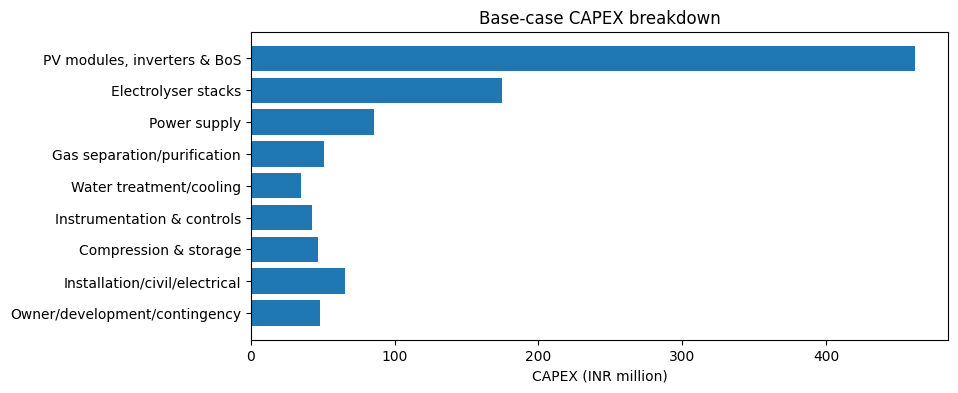

In [ ]:
capex_items = pd.DataFrame({
    'Item':['PV modules, inverters & BoS','Electrolyser stacks','Power supply','Gas separation/purification','Water treatment/cooling','Instrumentation & controls','Compression & storage','Installation/civil/electrical','Owner/development/contingency'],
    'INR_M':[462.0,175.0,85.6,50.6,35.0,42.8,46.7,65.3,48.1]
})
display(capex_items)
plt.barh(capex_items['Item'],capex_items['INR_M'])
plt.xlabel('CAPEX (INR million)'); plt.title('Base-case CAPEX breakdown')
plt.gca().invert_yaxis(); plt.show()

## 8. Discounted LCOH formula
LCOH is discounted lifetime cost divided by discounted lifetime hydrogen. CAPEX is spent in year 0; OPEX and stack replacement are discounted annually. The report gives the total discounted values; those are used for the reproducible arithmetic check.

In [ ]:
discount_rate = 0.10
project_life = 25
years = np.arange(1,project_life+1)
discount_factors = 1/(1+discount_rate)**years

# Illustrative cash-flow table using report's selected-year values.
cashflow_selected = pd.DataFrame({
    'Year':[0,1,2,10,17,25],
    'Hydrogen_t':[np.nan,272.2,271.6,266.9,262.5,257.4],
    'OPEX_INR_M':[1011.1,29.11,29.11,29.10,29.09,29.08],
    'Stack_replacement_INR_M':[0,0,0,0,175.0,0],
    'Discount_factor':[1.000,0.909,0.826,0.386,0.198,0.092]
})
display(cashflow_selected)
print('Published discounted cost total (INR M):',discounted_cost_M)
print('Published discounted hydrogen total (t):',discounted_h2_t)
print('Recomputed LCOH (INR/kg):',round(lcoh,2))

,Year,Hydrogen_t,OPEX_INR_M,Stack_replacement_INR_M,Discount_factor
0,0,NaN,1011.10,0.0,1.000
1,1,272.2,29.11,0.0,0.909
2,2,271.6,29.11,0.0,0.826
3,10,266.9,29.10,0.0,0.386
4,17,262.5,29.09,175.0,0.198
5,25,257.4,29.08,0.0,0.092


Published discounted cost total (INR M): 1309.9
Published discounted hydrogen total (t): 2430.2
Recomputed LCOH (INR/kg): 539.01


## 9. PV/electrolyser ratio scan


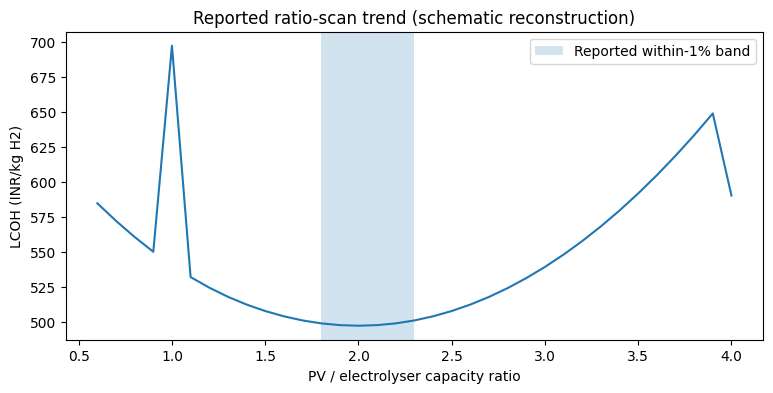

In [ ]:
ratios = np.arange(0.6,4.01,0.1)
# Schematic curve constrained to report's stated minimum and selected endpoints.
lcoh_ratio = 497 + 42*(ratios-2.0)**2 + 8*np.maximum(0,1.4-ratios)**2
lcoh_ratio[np.argmin(abs(ratios-1.0))] = 697
lcoh_ratio[np.argmin(abs(ratios-2.0))] = 497
lcoh_ratio[np.argmin(abs(ratios-4.0))] = 590
plt.plot(ratios,lcoh_ratio)
plt.axvspan(1.8,2.3,alpha=0.2,label='Reported within-1% band')
plt.xlabel('PV / electrolyser capacity ratio')
plt.ylabel('LCOH (INR/kg H2)')
plt.title('Reported ratio-scan trend (schematic reconstruction)')
plt.legend(); plt.show()

## 10. Scenario comparison from the report


,Scenario,PV_MWp,EL_MW,H2_t_y,CF_pct,Curtailment_pct,CAPEX_INR_M,OPEX_INR_M,LCOH_INR_kg,GWP_kgCO2e_kg
0,Small,5,3,149,30.7,9.1,582,20.6,598,2.44
1,Base,10,5,272,33.6,17.3,1011,29.1,539,2.59
2,Optimised,20,10,544,33.6,17.3,1922,47.7,497,2.59
3,Large,40,20,1089,33.6,17.3,3845,87.3,490,2.59
4,PV-heavy / max H2,40,10,662,40.7,49.9,2892,62.0,590,3.93
5,EL-heavy,12,10,378,23.6,3.1,1534,41.7,599,2.50


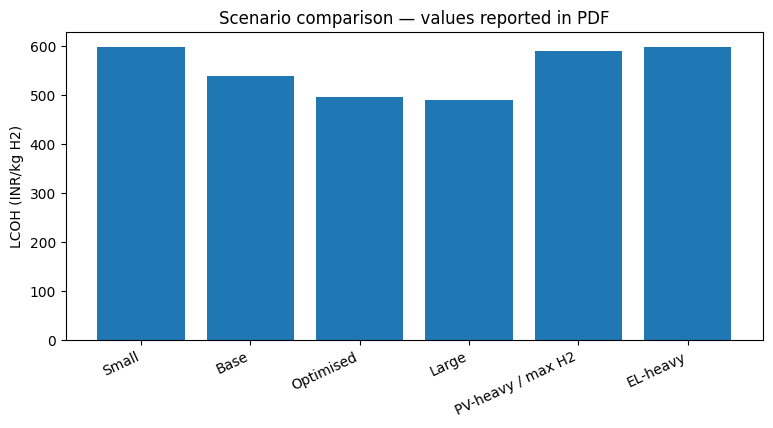

In [ ]:
scenarios = pd.DataFrame([
 ['Small',5,3,149,30.7,9.1,582,20.6,598,2.44],
 ['Base',10,5,272,33.6,17.3,1011,29.1,539,2.59],
 ['Optimised',20,10,544,33.6,17.3,1922,47.7,497,2.59],
 ['Large',40,20,1089,33.6,17.3,3845,87.3,490,2.59],
 ['PV-heavy / max H2',40,10,662,40.7,49.9,2892,62.0,590,3.93],
 ['EL-heavy',12,10,378,23.6,3.1,1534,41.7,599,2.50]
],columns=['Scenario','PV_MWp','EL_MW','H2_t_y','CF_pct','Curtailment_pct','CAPEX_INR_M','OPEX_INR_M','LCOH_INR_kg','GWP_kgCO2e_kg'])
display(scenarios)
plt.bar(scenarios.Scenario,scenarios.LCOH_INR_kg)
plt.ylabel('LCOH (INR/kg H2)'); plt.xticks(rotation=25,ha='right')
plt.title('Scenario comparison — values reported in PDF'); plt.show()

## 11. Optimization: selecting the best evaluated configuration

The optimization step compares candidate PV/electrolyser capacity combinations using the **LCOH calculated by the engineering model**. The values below are the scenario results reported in the project report (Table 6), not freshly recalculated values from the reconstructed hourly proxy. The code ranks the evaluated cases and selects the lowest-LCOH case in this comparison.



,Rank,Scenario,PV_MWp,EL_MW,H2_t_y,Curtailment_pct,LCOH_INR_kg,PV_to_EL_ratio
0,1,Large,40,20,1089,17.3,490,2.00
1,2,Optimised,20,10,544,17.3,497,2.00
2,3,Base,10,5,272,17.3,539,2.00
3,4,PV-heavy / max H2,40,10,662,49.9,590,4.00
4,5,Small,5,3,149,9.1,598,1.67
5,6,EL-heavy,12,10,378,3.1,599,1.20


Best evaluated configuration (among the scenarios listed):
PV capacity          : 40.0 MWp
Electrolyser capacity: 20.0 MW
PV / EL ratio        : 2.00
Hydrogen production  : 1089.0 tonnes/year
Curtailment          : 17.3%
Reported LCOH        : INR 490/kg H2


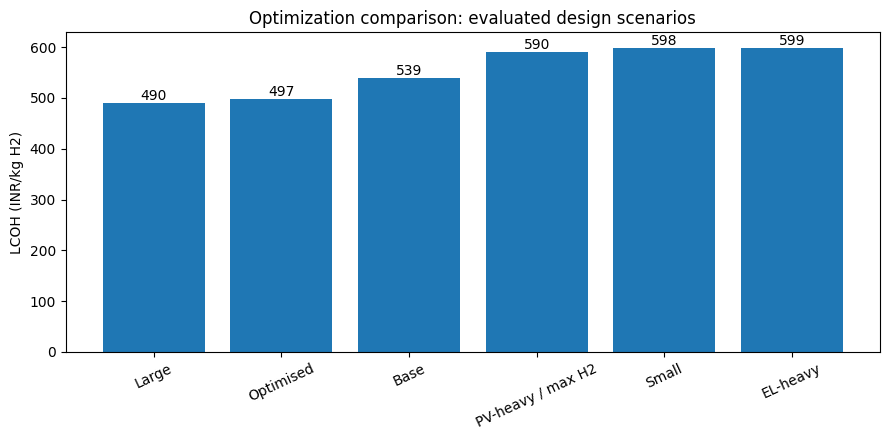

In [ ]:


optimization_results = scenarios[
    ['Scenario', 'PV_MWp', 'EL_MW', 'H2_t_y',
     'Curtailment_pct', 'LCOH_INR_kg']
].copy()

optimization_results['PV_to_EL_ratio'] = (
    optimization_results['PV_MWp'] / optimization_results['EL_MW']
)

optimization_results = optimization_results.sort_values(
    'LCOH_INR_kg', ascending=True
).reset_index(drop=True)

optimization_results.insert(
    0, 'Rank', np.arange(1, len(optimization_results) + 1)
)

display(optimization_results.round(2))

# Select the lowest-cost configuration among the evaluated scenarios.
best_case = optimization_results.iloc[0]

print('Best evaluated configuration (among the scenarios listed):')
print(f"PV capacity          : {best_case['PV_MWp']:.1f} MWp")
print(f"Electrolyser capacity: {best_case['EL_MW']:.1f} MW")
print(f"PV / EL ratio        : {best_case['PV_to_EL_ratio']:.2f}")
print(f"Hydrogen production  : {best_case['H2_t_y']:.1f} tonnes/year")
print(f"Curtailment          : {best_case['Curtailment_pct']:.1f}%")
print(f"Reported LCOH        : INR {best_case['LCOH_INR_kg']:.0f}/kg H2")

# Visual comparison: lower LCOH means a more economical candidate.
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(
    optimization_results['Scenario'],
    optimization_results['LCOH_INR_kg']
)
ax.set_ylabel('LCOH (INR/kg H2)')
ax.set_title('Optimization comparison: evaluated design scenarios')
ax.tick_params(axis='x', rotation=25)
ax.bar_label(bars, fmt='%.0f')
plt.tight_layout()
plt.show()


## 11. Sensitivity analysis — reported values
The PDF reports discount rate as the largest sensitivity, followed by electrolyser cost, specific energy consumption and PV cost. The bars below use the reported endpoint values.

,Parameter,Low_LCOH,High_LCOH,Swing
7,Water cost ±50%,538,540,2
6,Stack life 40k–80k h,533,556,23
5,Fixed O&M ±50%,519,559,40
4,Solar yield ±10%,518,568,50
3,PV capital cost ±20%,494,584,90
2,Specific energy 48–58 kWh/kg,498,601,103
1,Electrolyser cost ±20%,483,595,112
0,Discount rate 7–13%,452,634,182


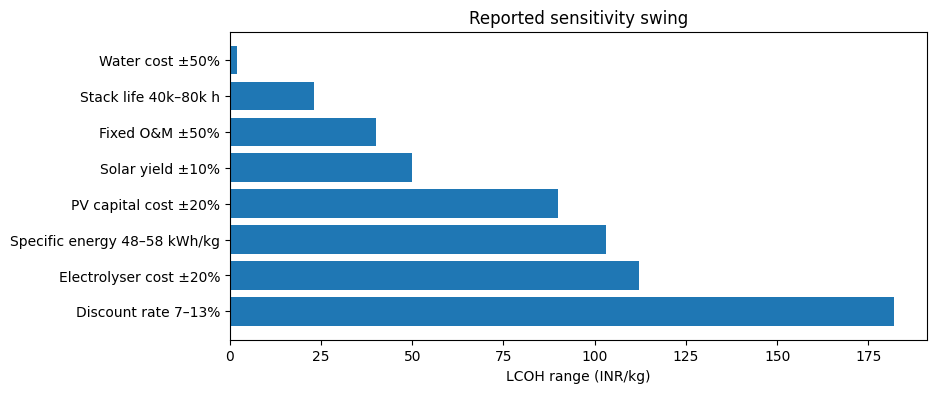

In [ ]:
sensitivity = pd.DataFrame([
 ['Discount rate 7–13%',452,634],
 ['Electrolyser cost ±20%',483,595],
 ['Specific energy 48–58 kWh/kg',498,601],
 ['PV capital cost ±20%',494,584],
 ['Solar yield ±10%',518,568],
 ['Fixed O&M ±50%',519,559],
 ['Stack life 40k–80k h',533,556],
 ['Water cost ±50%',538,540]
],columns=['Parameter','Low_LCOH','High_LCOH'])
sensitivity['Swing'] = sensitivity.High_LCOH-sensitivity.Low_LCOH
display(sensitivity.sort_values('Swing',ascending=True))
plt.barh(sensitivity.Parameter,sensitivity.Swing)
plt.xlabel('LCOH range (INR/kg)'); plt.title('Reported sensitivity swing')
plt.show()

## 12. Environmental screening calculation
The report estimates 2.59 kg CO₂e/kg H₂ for the base case: PV 2.26, electrolyser stacks including replacement 0.15, balance of plant/compression 0.11 and leakage 0.06. These are screening estimates with substantial assumed embodied-emission factors.

Total screening GWP: 2.5799999999999996 kg CO2e/kg H2


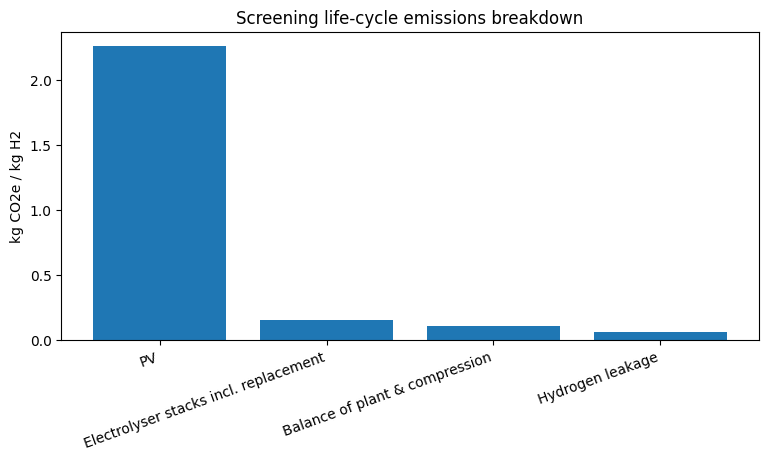

In [ ]:
gwp_components = pd.DataFrame({
    'Source':['PV','Electrolyser stacks incl. replacement','Balance of plant & compression','Hydrogen leakage'],
    'kgCO2e_per_kgH2':[2.26,0.15,0.11,0.06]
})
print('Total screening GWP:',gwp_components['kgCO2e_per_kgH2'].sum(),'kg CO2e/kg H2')
plt.bar(gwp_components.Source,gwp_components['kgCO2e_per_kgH2'])
plt.ylabel('kg CO2e / kg H2'); plt.xticks(rotation=20,ha='right')
plt.title('Screening life-cycle emissions breakdown'); plt.show()

## 13. Machine-learning surrogate — regenerated demonstration


In [ ]:
rng = np.random.default_rng(2026)
n = 3000
ml = pd.DataFrame({
 'PV_EL_ratio':rng.uniform(0.8,5.0,n),
 'EL_MW':rng.uniform(1,30,n),
 'Solar_yield':rng.uniform(1599,1955,n),
 'SEC0':rng.uniform(48,58,n),
 'PV_cost':rng.uniform(35000,60000,n),
 'EL_cost_USD_kW':rng.uniform(500,1100,n),
 'Discount_rate':rng.uniform(0.07,0.13,n),
 'Stack_life_h':rng.uniform(40000,80000,n),
 'PV_capacity_MWp':rng.uniform(2,60,n)
})
# Transparent synthetic target function: illustrative only, not the original engineering solver.
ratio=ml.PV_EL_ratio
ml['LCOH']=(500 + 42*(ratio-2.0)**2
            + 0.003*(ml.EL_cost_USD_kW-800)
            + 900*(ml.Discount_rate-0.10)
            + 2.0*(ml.SEC0-52)
            - 0.05*(ml.Solar_yield-1777)
            + 0.0008*(ml.PV_cost-46200)
            + 8*(60000-ml.Stack_life_h)/20000
            + rng.normal(0,10,n))
ml.head()

,PV_EL_ratio,EL_MW,Solar_yield,SEC0,PV_cost,EL_cost_USD_kW,Discount_rate,Stack_life_h,PV_capacity_MWp,LCOH
0,1.551526,3.893679,1757.015775,53.493785,54369.374755,533.328511,0.103948,69682.917735,3.452141,514.602797
1,3.487635,15.064075,1841.887986,55.511800,58572.010897,998.824802,0.081353,41327.622343,4.174754,586.145271
2,2.762527,9.354822,1813.655608,57.438111,51365.011089,889.291061,0.084503,56095.911192,21.483924,518.467071
3,2.356102,8.543206,1894.057881,54.974129,48602.059827,700.623549,0.109133,50667.797444,49.682663,521.752852
4,2.290653,17.769577,1821.233472,56.271341,37575.004486,706.691491,0.088741,63748.840660,28.003235,488.218796


In [ ]:
X=ml.drop(columns='LCOH')
y=ml['LCOH']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=7)
models={
 'Linear regression':LinearRegression(),
 'Random forest':RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=7),
 'Gradient boosting':GradientBoostingRegressor(n_estimators=600,max_depth=3,learning_rate=0.1,random_state=7)
}
rows=[]
kf=KFold(n_splits=5,shuffle=True,random_state=7)
for name,model in models.items():
    cv=cross_val_score(model,X_train,y_train,cv=kf,scoring='r2')
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    rows.append([name,cv.mean(),r2_score(y_test,pred),mean_absolute_error(y_test,pred),
                 mean_squared_error(y_test,pred)**0.5])
    if name=='Gradient boosting':
        gb=model
        gb_pred=pred
ml_metrics=pd.DataFrame(rows,columns=['Model','CV R2','Test R2','MAE INR/kg','RMSE INR/kg'])
display(ml_metrics)

,Model,CV R2,Test R2,MAE INR/kg,RMSE INR/kg
0,Linear regression,0.736558,0.757721,46.451209,55.010962
1,Random forest,0.985789,0.987478,9.956530,12.506063
2,Gradient boosting,0.989103,0.990033,8.882053,11.157503


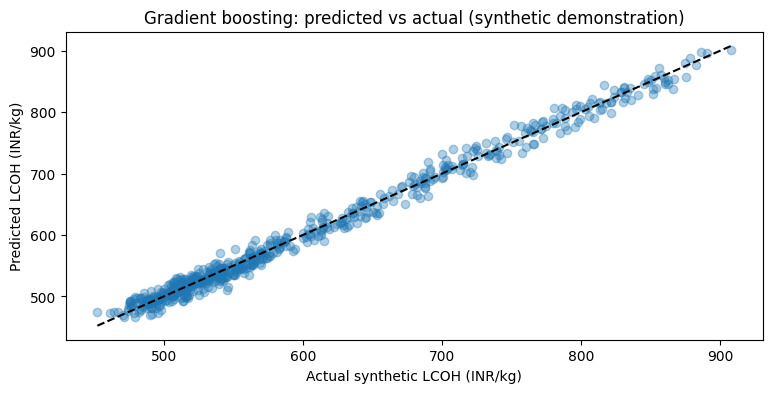

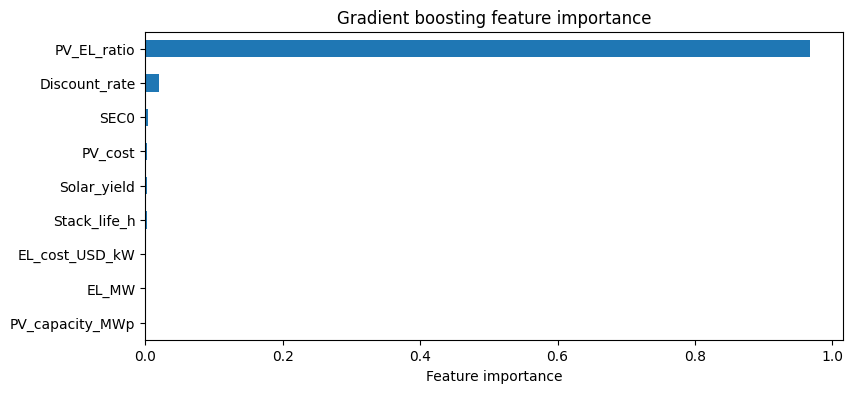

In [ ]:
plt.scatter(y_test,gb_pred,alpha=0.35)
lo=min(y_test.min(),gb_pred.min()); hi=max(y_test.max(),gb_pred.max())
plt.plot([lo,hi],[lo,hi],'k--')
plt.xlabel('Actual synthetic LCOH (INR/kg)')
plt.ylabel('Predicted LCOH (INR/kg)')
plt.title('Gradient boosting: predicted vs actual (synthetic demonstration)')
plt.show()

importance=pd.Series(gb.feature_importances_,index=X.columns).sort_values()
importance.plot(kind='barh')
plt.xlabel('Feature importance'); plt.title('Gradient boosting feature importance')
plt.show()

## 14. Final validation checklist
- PV yield in the report is a tuned proxy, not NASA POWER measurement.
- 10 MWp × 1,777 kWh/kWp/year = 17.77 GWh/year PV generation.
- Base electrolyser input is reported as 14.70 GWh/year.
- Base hydrogen production is reported as 272.2 tonnes/year.
- Practical water use is 20 kg/kg H₂; theoretical stoichiometric water is 8.94 kg/kg H₂.
- CAPEX is ₹1,011.1 million and year-1 OPEX is ₹29.1 million.
- Discounted LCOH arithmetic: ₹1,309.9 million / 2,430.2 tonnes = approximately ₹539/kg.
- Ratio optimisation minimum is near 2.0; absolute-size optimum is boundary-dependent because scale and fixed-staff assumptions affect the result.



## 15. Report Figure 2 — process-flow diagram



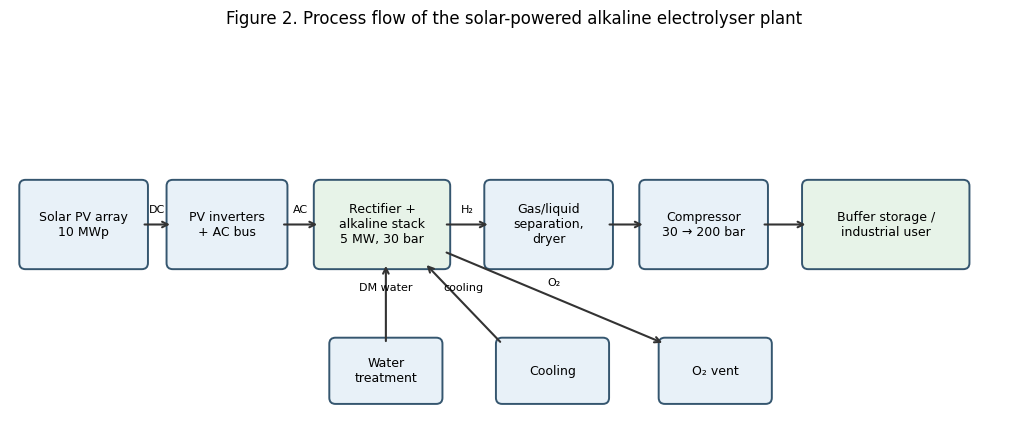

In [ ]:

import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(13,5))
ax.set_xlim(0, 13); ax.set_ylim(0, 5); ax.axis("off")

def unit(x,y,w,h,label,fc="#e8f1f8"):
    box = patches.FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.08",
                                 linewidth=1.4,edgecolor="#35566f",facecolor=fc)
    ax.add_patch(box)
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9,wrap=True)

def arrow(x1,y1,x2,y2,label=None):
    ax.annotate("",xy=(x2,y2),xytext=(x1,y1),
                arrowprops=dict(arrowstyle="->",lw=1.5,color="#333"))
    if label: ax.text((x1+x2)/2,(y1+y2)/2+0.16,label,ha="center",fontsize=8)

unit(.2,2.0,1.5,1.0,"Solar PV array\n10 MWp")
unit(2.1,2.0,1.4,1.0,"PV inverters\n+ AC bus")
unit(4.0,2.0,1.6,1.0,"Rectifier +\nalkaline stack\n5 MW, 30 bar", "#e7f3e8")
unit(6.2,2.0,1.5,1.0,"Gas/liquid\nseparation,\ndryer")
unit(8.2,2.0,1.5,1.0,"Compressor\n30 → 200 bar")
unit(10.3,2.0,2.0,1.0,"Buffer storage /\nindustrial user", "#e7f3e8")
arrow(1.7,2.5,2.1,2.5,"DC"); arrow(3.5,2.5,4.0,2.5,"AC")
arrow(5.6,2.5,6.2,2.5,"H₂"); arrow(7.7,2.5,8.2,2.5)
arrow(9.7,2.5,10.3,2.5)
unit(4.2,.25,1.3,.7,"Water\ntreatment")
unit(6.35,.25,1.3,.7,"Cooling")
unit(8.45,.25,1.3,.7,"O₂ vent")
arrow(4.85,.95,4.85,2.0,"DM water")
arrow(6.35,.95,5.35,2.0,"cooling")
arrow(5.6,2.15,8.45,.95,"O₂")
ax.set_title("Figure 2. Process flow of the solar-powered alkaline electrolyser plant",fontsize=12)
plt.show()


## 16. Report Figure 3 — CAPEX and LCOH component breakdown
The CAPEX plot is already produced in Section 7. This additional chart reproduces the report's discounted LCOH component split (page 6): CAPEX ₹416/kg, fixed O&M/insurance/staff ₹107/kg, stack replacement ₹14/kg and water ₹2/kg. Values are transcribed from the report.


,Component,INR_per_kg
0,CAPEX,416
1,"Fixed O&M, insurance & staff",107
2,Stack replacement,14
3,Water,2


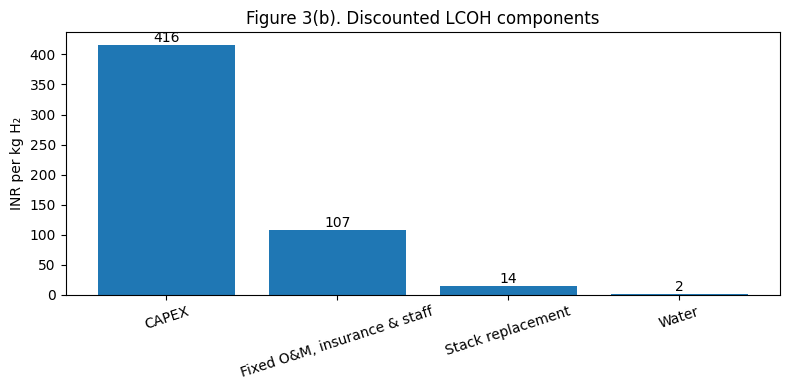

In [ ]:

lcoh_components = pd.DataFrame({
    "Component":["CAPEX","Fixed O&M, insurance & staff","Stack replacement","Water"],
    "INR_per_kg":[416,107,14,2]
})
display(lcoh_components)
fig, ax = plt.subplots(figsize=(8,4))
bars=ax.bar(lcoh_components.Component,lcoh_components.INR_per_kg)
ax.set_ylabel("INR per kg H₂"); ax.set_title("Figure 3(b). Discounted LCOH components")
ax.tick_params(axis="x",rotation=18)
for b,v in zip(bars,lcoh_components.INR_per_kg):
    ax.text(b.get_x()+b.get_width()/2,v+5,str(v),ha="center")
plt.tight_layout(); plt.show()


## 17. Report Figure 5 — LCOH over PV and electrolyser capacity



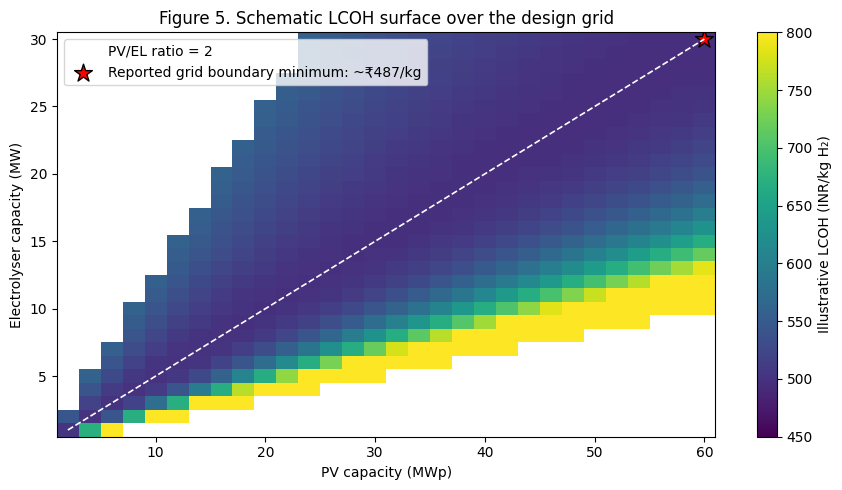

In [ ]:

pv_grid = np.arange(2, 62, 2)
el_grid = np.arange(1, 31, 1)
PVG, ELG = np.meshgrid(pv_grid, el_grid)
R = PVG / ELG
# Smooth illustrative surface; anchored near the report's ratio-2 low-cost band.
# The full-grid boundary result (60 MWp, 30 MW, ~₹487/kg) is called out separately.
Z = 497 + 42*(R-2.0)**2 + 0.45*(10/ELG-1) + 0.10*(30-ELG)
Z[(R < 0.8) | (R > 6)] = np.nan
fig, ax = plt.subplots(figsize=(9,5))
im=ax.pcolormesh(PVG,ELG,Z,shading="auto",cmap="viridis",vmin=450,vmax=800)
ax.plot([2,60],[1,30],"w--",lw=1.2,label="PV/EL ratio = 2")
ax.scatter([60],[30],marker="*",s=180,c="red",edgecolors="black",
           label="Reported grid boundary minimum: ~₹487/kg")
ax.set_xlabel("PV capacity (MWp)"); ax.set_ylabel("Electrolyser capacity (MW)")
ax.set_title("Figure 5. Schematic LCOH surface over the design grid")
fig.colorbar(im,ax=ax,label="Illustrative LCOH (INR/kg H₂)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()


## 18. Report Figure 6 — one-at-a-time sensitivity
This chart uses the low and high LCOH endpoints listed in the report (page 8). The vertical reference line is the base-case LCOH of ₹539/kg.


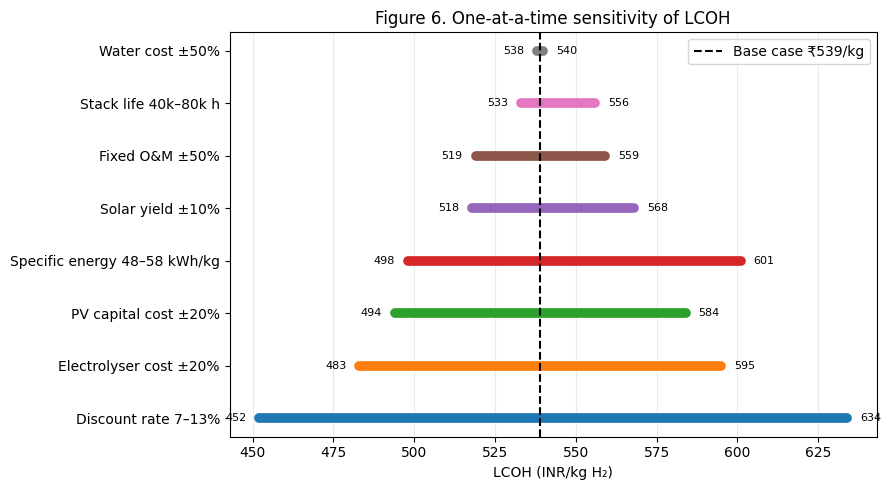

In [ ]:

fig, ax = plt.subplots(figsize=(9,5))
sens_plot=sensitivity.sort_values("Low_LCOH")
for y, row in enumerate(sens_plot.itertuples()):
    ax.plot([row.Low_LCOH,row.High_LCOH],[y,y],lw=7,solid_capstyle="round")
    ax.text(row.Low_LCOH-4,y,f"{row.Low_LCOH}",ha="right",va="center",fontsize=8)
    ax.text(row.High_LCOH+4,y,f"{row.High_LCOH}",ha="left",va="center",fontsize=8)
ax.axvline(539,color="black",ls="--",label="Base case ₹539/kg")
ax.set_yticks(range(len(sens_plot))); ax.set_yticklabels(sens_plot.Parameter)
ax.set_xlabel("LCOH (INR/kg H₂)")
ax.set_title("Figure 6. One-at-a-time sensitivity of LCOH")
ax.legend(); ax.grid(axis="x",alpha=.25); plt.tight_layout(); plt.show()


## 19. Report Figure 7 — screening life-cycle emissions



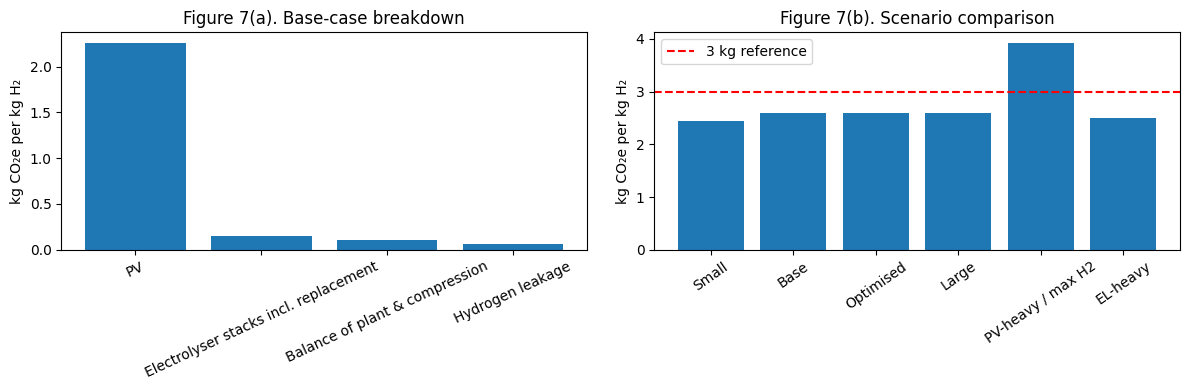

In [ ]:

fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(gwp_components.Source,gwp_components["kgCO2e_per_kgH2"])
axes[0].set_ylabel("kg CO₂e per kg H₂")
axes[0].set_title("Figure 7(a). Base-case breakdown")
axes[0].tick_params(axis="x",rotation=25)
axes[1].bar(scenarios.Scenario,scenarios.GWP_kgCO2e_kg)
axes[1].axhline(3,color="red",ls="--",label="3 kg reference")
axes[1].set_ylabel("kg CO₂e per kg H₂")
axes[1].set_title("Figure 7(b). Scenario comparison")
axes[1].tick_params(axis="x",rotation=35)
axes[1].legend()
plt.tight_layout(); plt.show()


## 20. Report Figure 8 — ML surrogate diagnostics



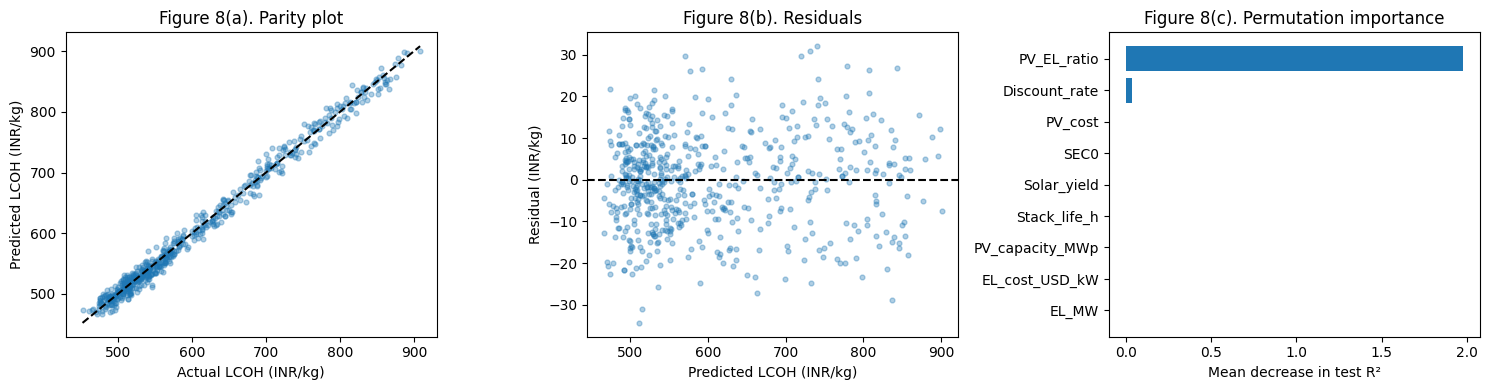

In [ ]:

from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].scatter(y_test,gb_pred,alpha=.35,s=12)
lo=min(y_test.min(),gb_pred.min()); hi=max(y_test.max(),gb_pred.max())
axes[0].plot([lo,hi],[lo,hi],"k--")
axes[0].set_xlabel("Actual LCOH (INR/kg)")
axes[0].set_ylabel("Predicted LCOH (INR/kg)")
axes[0].set_title("Figure 8(a). Parity plot")

residuals=gb_pred-y_test.to_numpy()
axes[1].scatter(gb_pred,residuals,alpha=.35,s=12)
axes[1].axhline(0,color="black",ls="--")
axes[1].set_xlabel("Predicted LCOH (INR/kg)")
axes[1].set_ylabel("Residual (INR/kg)")
axes[1].set_title("Figure 8(b). Residuals")

perm=permutation_importance(gb,X_test,y_test,n_repeats=8,random_state=2026,scoring="r2")
perm_s=pd.Series(perm.importances_mean,index=X.columns).sort_values()
axes[2].barh(perm_s.index,perm_s.values)
axes[2].set_xlabel("Mean decrease in test R²")
axes[2].set_title("Figure 8(c). Permutation importance")
plt.tight_layout(); plt.show()


## 21. Report Figure 9 — engineering model vs ML surrogate grid


/tmp/ipykernel_1397/3149947307.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


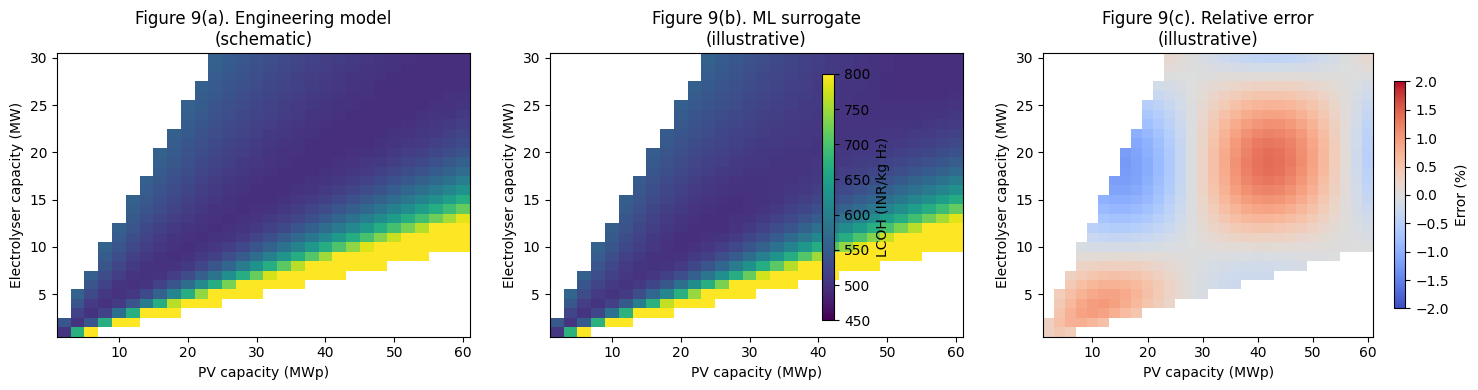

In [ ]:

# A schematic surrogate surface, deliberately distinguished from the unavailable original.
Z_ml = Z + 7*np.sin(PVG/9.0)*np.cos(ELG/6.0)
ERR = 100*(Z_ml-Z)/Z
fig, axes = plt.subplots(1,3,figsize=(15,4))
p1=axes[0].pcolormesh(PVG,ELG,Z,shading="auto",cmap="viridis",vmin=450,vmax=800)
axes[0].set_title("Figure 9(a). Engineering model\n(schematic)")
p2=axes[1].pcolormesh(PVG,ELG,Z_ml,shading="auto",cmap="viridis",vmin=450,vmax=800)
axes[1].set_title("Figure 9(b). ML surrogate\n(illustrative)")
p3=axes[2].pcolormesh(PVG,ELG,ERR,shading="auto",cmap="coolwarm",vmin=-2,vmax=2)
axes[2].set_title("Figure 9(c). Relative error\n(illustrative)")
for ax in axes:
    ax.set_xlabel("PV capacity (MWp)"); ax.set_ylabel("Electrolyser capacity (MW)")
fig.colorbar(p1,ax=axes[:2],label="LCOH (INR/kg H₂)",shrink=.8)
fig.colorbar(p3,ax=axes[2],label="Error (%)",shrink=.8)
plt.tight_layout(); plt.show()
